In [25]:
# library imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# read data
all = pd.read_csv("data/top_100.csv")
ones = pd.read_csv("data/billboard.csv")

In [3]:
ones.shape

(1177, 105)

In [4]:
ones.columns

Index(['song', 'artist', 'date', 'weeks_at_number_one', 'non_consecutive',
       'rating_1', 'rating_2', 'rating_3', 'overall_rating', 'divisiveness',
       ...
       'featured_in_a_then_contemporary_play', 'written_for_a_film',
       'featured_in_a_then_contemporary_film', 'written_for_a_t_v_show',
       'featured_in_a_then_contemporary_t_v_show', 'associated_with_dance',
       'topped_the_charts_by_multiple_artist', 'double_a_side',
       'eurovision_entry', 'u_s_artwork'],
      dtype='str', length=105)

remove rows missing lyrical_topic

In [5]:
ones = ones.dropna(subset="lyrical_topic")
ones.shape

(1151, 105)

In [6]:
lyrical_topics = ones["lyrical_topic"]
topics_dict = {}

find most common topics for all time

In [7]:
for cell in lyrical_topics:
    cell = str(cell)
    if ";" in cell:      # multiple
        cell = cell.split(";")
    else:                        # one
        cell = [cell]
    #print(cell)
    for top in cell:
        #print(top)
        if top in topics_dict:
            topics_dict[top] += 1
        else:
            topics_dict[top] = 1

In [8]:
topics_list = []
for cell in lyrical_topics:
    cell = str(cell)
    if ";" in cell:      # multiple
        cell = cell.split(";")
    else:                        # one
        cell = [cell]
    #print(cell)
    for top in cell:
        topics_list.append(top)

topics_list = pd.Series(topics_list)
# overall most common topics
topics_list.value_counts()

Lust/Sex             271
Love                 269
Lost Love            252
Longing for Love     108
Bad Relationships     82
                    ... 
Thrift Shopping        1
Happiness              1
Bad Relationship       1
Addicition             1
Magic                  1
Name: count, Length: 111, dtype: int64

df for each of top 5 all-time topics

In [9]:
lust_sex = ones[ones["lyrical_topic"].str.contains("Lust/Sex")]
love = ones[ones["lyrical_topic"].str.contains("Love")]
lost_love = ones[ones["lyrical_topic"].str.contains("Lost Love")]
longing_love = ones[ones["lyrical_topic"].str.contains("Longing for Love")]
bad_relate = ones[ones["lyrical_topic"].str.contains("Bad Relationships")]

In [10]:
ones["date"].max()

'2025-01-11T00:00:00Z'

seperate into 20-year chunks

In [11]:
ones_58 = ones[(ones["date"] >= "1958-08-04T00:00:00Z") & (ones["date"] < "1978-08-04T00:00:00Z")]
ones_78 = ones[(ones["date"] >= "1978-08-04T00:00:00Z") & (ones["date"] < "1998-08-04T00:00:00Z")]
ones_98 = ones[(ones["date"] >= "1998-08-04T00:00:00Z") & (ones["date"] < "2018-08-04T00:00:00Z")]
ones_18 = ones[(ones["date"] >= "2018-08-04T00:00:00Z") & (ones["date"] < "2025-01-11T00:00:00Z")]
ones_58.shape

(425, 105)

count topics for each chunk

In [12]:
lyrical_topics_58 = ones_58["lyrical_topic"]
topics_list_58 = []
for cell in lyrical_topics_58:
    cell = str(cell)
    if ";" in cell:      # multiple
        cell = cell.split(";")
    else:                        # one
        cell = [cell]
    #print(cell)
    for top in cell:
        topics_list_58.append(top)

topics_list_58 = pd.Series(topics_list_58)

In [13]:
lyrical_topics_78 = ones_78["lyrical_topic"]
topics_list_78 = []
for cell in lyrical_topics_78:
    cell = str(cell)
    if ";" in cell:      # multiple
        cell = cell.split(";")
    else:                        # one
        cell = [cell]
    #print(cell)
    for top in cell:
        topics_list_78.append(top)

topics_list_78 = pd.Series(topics_list_78)

In [14]:
lyrical_topics_98 = ones_98["lyrical_topic"]
topics_list_98 = []
for cell in lyrical_topics_98:
    cell = str(cell)
    if ";" in cell:      # multiple
        cell = cell.split(";")
    else:                        # one
        cell = [cell]
    #print(cell)
    for top in cell:
        topics_list_98.append(top)

topics_list_98 = pd.Series(topics_list_98)

In [15]:
lyrical_topics_18 = ones_18["lyrical_topic"]
topics_list_18 = []
for cell in lyrical_topics_18:
    cell = str(cell)
    if ";" in cell:      # multiple
        cell = cell.split(";")
    else:                        # one
        cell = [cell]
    #print(cell)
    for top in cell:
        topics_list_18.append(top)

topics_list_18 = pd.Series(topics_list_18)

In [16]:
topics_list_58.value_counts()[0:10]

Love                 133
Lost Love             89
Lust/Sex              74
Longing for Love      36
Death                 23
Dancing               23
Bad Relationships     17
Growing Up            11
Murder                 9
Forbidden Love         9
Name: count, dtype: int64

In [17]:
topics_list_78.value_counts()[0:10]

Love                 95
Lost Love            92
Lust/Sex             89
Longing for Love     41
Bad Relationships    23
Dancing              21
Partying             12
Death                11
Badassery            11
Empowerment          10
Name: count, dtype: int64

In [18]:
topics_list_98.value_counts()[0:10]

Lust/Sex             79
Lost Love            44
Love                 34
Bad Relationships    31
Bragging             30
Partying             29
Dancing              22
Longing for Love     21
Empowerment          17
Infidelity           14
Name: count, dtype: int64

In [19]:
topics_list_18.value_counts()[0:10]

Lust/Sex             29
Lost Love            27
Bragging             21
Bad Relationships    11
Longing for Love      9
Partying              9
Empowerment           6
Dancing               6
Love                  6
Materialism           5
Name: count, dtype: int64

graph top 10 topics per chunk

Text(0.5, 1.0, 'Love - 1')

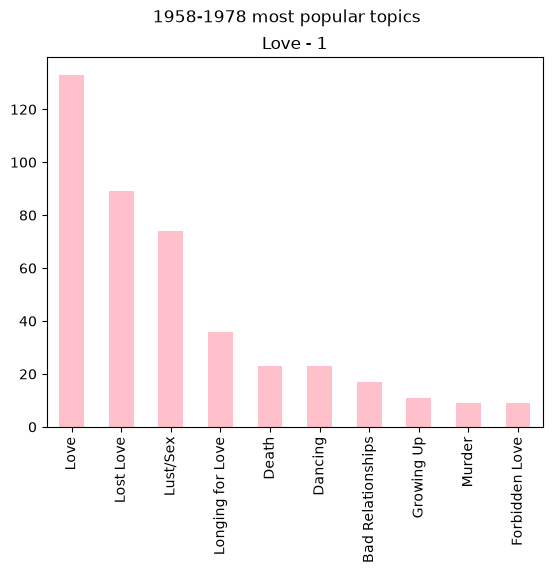

In [ ]:
topics_list_58.value_counts()[0:10].plot(kind='bar', color='pink')
plt.suptitle("1958-1978 most popular topics")
plt.title("Love - 1, LS - 3")

Text(0.5, 1.0, 'Love - 1')

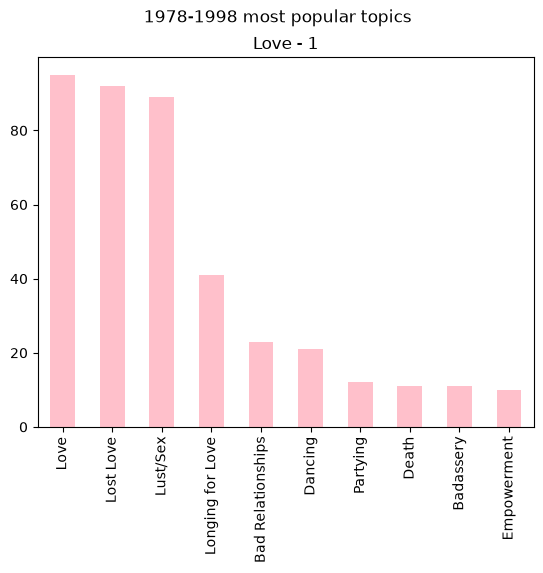

In [ ]:
topics_list_78.value_counts()[0:10].plot(kind='bar', color='pink')
plt.suptitle("1978-1998 most popular topics")
plt.title("Love - 1, LS - 3")

Text(0.5, 1.0, 'Love - 3')

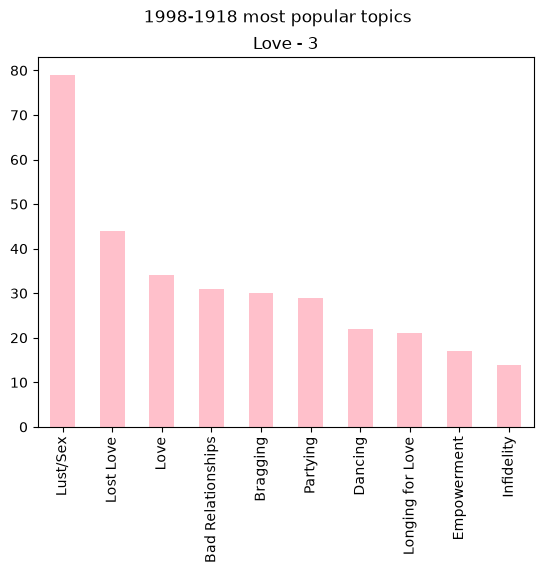

In [ ]:
topics_list_98.value_counts()[0:10].plot(kind='bar', color='pink')
plt.suptitle("1998-1918 most popular topics")
plt.title("Love - 3, LS - 1")

Text(0.5, 1.0, 'Love - 9')

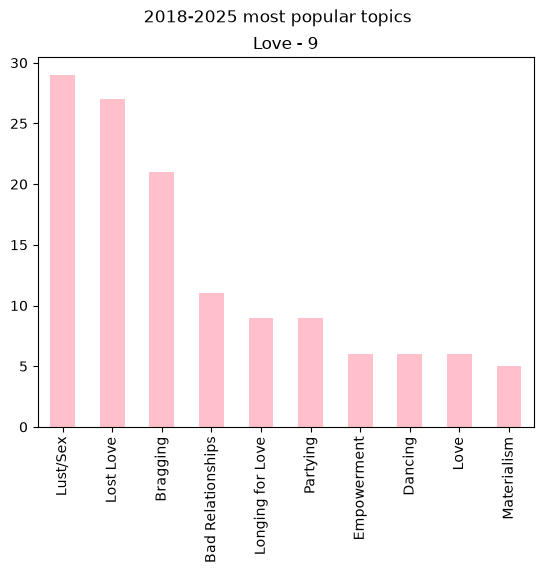

In [ ]:
topics_list_18.value_counts()[0:10].plot(kind='bar', color='pink')
plt.suptitle("2018-2025 most popular topics")
plt.title("Love - 9, LS - 1")

<Axes: xlabel='None', ylabel='count'>

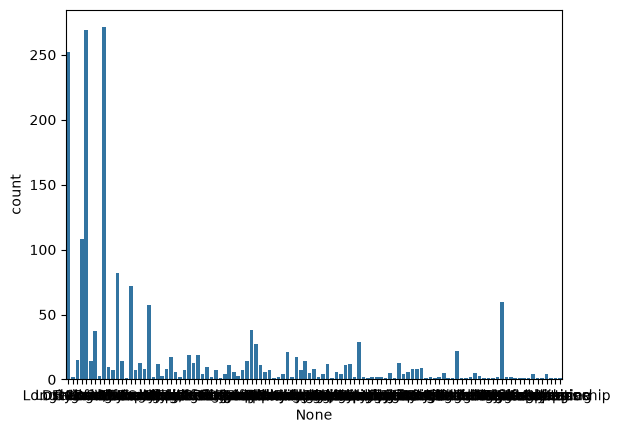

In [26]:
sns.countplot(x=topics_list)